# **실습 개요**

여러분은 카드사 이상거래 탐지팀(FDS, Fraud Detection System)에 새로 합류한 데이터 분석가입니다.<br>
최근 온라인 쇼핑, 해외 결제가 늘어나면서 도난/복제 카드로 인한 **이상 거래**가 꾸준히 증가하고 있습니다.<br>
카드사는 거래가 발생하는 즉시 사기 여부를 판단하여 필요한 경우 승인을 보류해야 합니다.

여러분에게 주어진 임무는 최근 6개월간의 결제 거래 로그를 바탕으로,
<br>새로운 거래가 들어왔을 때 이를 **사기(1) / 정상(0)** 으로 분류하는 모델을 만드는 것입니다.

실시간 거래 시스템의 특성상 일부 로그에는 결측치가 있고, 통신 오류로 인한 이상치, 중복 전송된 로그도 섞여 있습니다.<br>
이를 정제한 뒤 모델을 학습시키고, 실제 신규 거래 데이터(검증 데이터)에 대해 모델의 성능을 평가해봅시다.

## **데이터셋 설명**

| 컬럼명 | 설명 |
|---|---|
| transaction_id | 거래 고유 ID |
| transaction_amount | 거래 금액 (원) |
| transaction_hour | 거래 발생 시각 (0~23시) |
| merchant_category | 가맹점 업종 (온라인쇼핑, 전자기기, 편의점, 주유소, 여행/항공, 레스토랑, 생활용품) |
| customer_age | 고객 나이 |
| account_tenure_days | 카드 계좌 개설 후 경과 일수 |
| avg_monthly_spending | 고객의 평균 월 지출액 (원) |
| estimated_card_limit | 추정 카드 한도 (원) |
| distance_from_home_km | 등록된 집 주소로부터 결제 위치까지의 거리 (km) |
| is_foreign_transaction | 해외 거래 여부 (0 = 국내, 1 = 해외) |
| num_transactions_last_24h | 최근 24시간 내 거래 횟수 |
| time_since_last_transaction_min | 직전 거래로부터 경과 시간 (분) |
| is_fraud | **[target]** 사기 거래 여부 (0 = 정상, 1 = 사기) |

## **데이터셋 URL**
https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/credit_card_fraud.csv

### **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

**Q1. credit_card_fraud.csv를 읽어온 뒤 첫 5개의 행을 출력하세요.**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/credit_card_fraud.csv')
df.head()

,transaction_id,transaction_amount,transaction_hour,merchant_category,customer_age,account_tenure_days,avg_monthly_spending,estimated_card_limit,distance_from_home_km,is_foreign_transaction,num_transactions_last_24h,time_since_last_transaction_min,is_fraud
0,100387,15500.0,21,레스토랑,22.0,626,555000.0,1700000.0,30.5,0,2,20.7,0
1,100995,720700.0,6,전자기기,48.0,1459,487200.0,1614000.0,8.0,0,2,139.7,1
2,100152,24800.0,9,주유소,34.0,1614,333100.0,1085000.0,9.2,0,1,23.8,0
3,100652,45200.0,9,주유소,55.0,1881,150000.0,403000.0,1.2,0,1,273.6,0
4,100595,377900.0,1,여행/항공,36.0,853,100400.0,313000.0,55.8,0,6,302.1,1


**Q2. 데이터의 전반적인 정보를 출력합니다.**

In [2]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1185 entries, 0 to 1184
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   transaction_id                   1185 non-null   int64  
 1   transaction_amount               1150 non-null   float64
 2   transaction_hour                 1185 non-null   int64  
 3   merchant_category                1185 non-null   str    
 4   customer_age                     1162 non-null   float64
 5   account_tenure_days              1185 non-null   int64  
 6   avg_monthly_spending             1137 non-null   float64
 7   estimated_card_limit             1185 non-null   float64
 8   distance_from_home_km            1126 non-null   float64
 9   is_foreign_transaction           1185 non-null   int64  
 10  num_transactions_last_24h        1185 non-null   int64  
 11  time_since_last_transaction_min  1185 non-null   float64
 12  is_fraud                       

**Q3. 수치형 컬럼들의 기초 통계량을 확인하세요.**

In [3]:
# code here
df.describe()

,transaction_id,transaction_amount,transaction_hour,customer_age,account_tenure_days,avg_monthly_spending,estimated_card_limit,distance_from_home_km,is_foreign_transaction,num_transactions_last_24h,time_since_last_transaction_min,is_fraud
count,1185.000000,1.150000e+03,1185.000000,1162.000000,1185.000000,1.137000e+03,1.185000e+03,1126.000000,1185.000000,1185.000000,1185.000000,1185.000000
mean,100577.201688,2.456782e+05,11.369620,47.270224,2003.594937,2.850731e+05,8.619392e+05,87.622913,0.089451,2.196624,173.919747,0.099578
std,331.939192,1.281509e+06,6.924308,18.142919,1151.436995,1.663641e+05,4.933594e+05,690.321780,0.285515,1.491300,177.274140,0.299563
min,100001.000000,1.200000e+03,0.000000,0.000000,19.000000,5.000000e+04,3.000000e+05,0.100000,0.000000,0.000000,0.000000,0.000000
25%,100290.000000,3.032500e+04,6.000000,33.000000,1029.000000,1.616000e+05,4.850000e+05,7.400000,0.000000,1.000000,51.300000,0.000000
50%,100578.000000,6.920000e+04,11.000000,47.000000,1969.000000,2.575000e+05,7.680000e+05,14.500000,0.000000,2.000000,119.200000,0.000000
75%,100863.000000,1.546500e+05,17.000000,61.000000,2985.000000,3.691000e+05,1.102000e+06,24.975000,0.000000,3.000000,242.800000,0.000000
max,101150.000000,1.499760e+07,23.000000,200.000000,3997.000000,1.154400e+06,3.659000e+06,8725.700000,1.000000,8.000000,1307.100000,1.000000


## **2. 데이터 분석하기**

### **2-1. 데이터 탐색**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.


**colab에서 csv 파일 다운로드하기**
```
from google.colab import files
files.download("submission.csv")
```

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 업종(merchant_category)별 평균 거래 금액을 소수점 2자리까지 찾아 주세요.

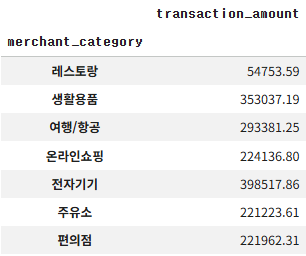

In [18]:
# code here
df.groupby("merchant_category")["transaction_amount"].mean().round(2).to_csv("anomal01.csv")

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 업종(merchant_category)별 사기 거래의 비율을 소수점 2자리까지 백분율로 구한 후, 비율이 높은 순으로 정렬해 주세요.

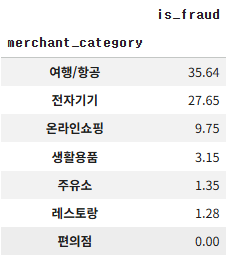

In [17]:
# code here
(df.groupby("merchant_category")["is_fraud"].mean() * 100).round(2).sort_values(ascending=False).to_csv("anomal02.csv")

**Q3. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 계좌 개설 후 90일 이내인 '신규 계좌'와 그 외 계좌의 사기 거래 비율을 각각 소수점 2자리까지 구해 주세요. (백분율)

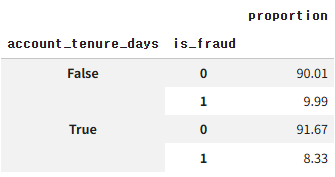

In [34]:
# code here
(df.groupby(df["account_tenure_days"] < 90)["is_fraud"].value_counts(normalize=True) * 100).round(2).to_csv("anomal03.csv")

**Q4. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- 근 24시간 내 가장 거래가 많았던 상위 5건을 찾아, 해당 거래들의 사기 비율을 백분율로 소수점 2자리까지 확인합니다.
- 해외거래이면서, 평수 지출 대비 1.5배 이상, 그리고 최근 24시간내 거래 3회 이상인 거래를 "고위험 거래"라고 했을 때, <br>이 조건에 해당하는 사기 비율을 구해 주세요. (소수점2자리, 백분율)

그리고 "ans" 컬럼에 순서대로 저장하여 제출합니다.

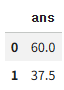

In [59]:
ans = []

In [ ]:
# code here
# df.loc[df["num_transcation_last_24h"].nlargest(5).index]["is_fraud"]
q2_1 = (df.sort_values("num_transactions_last_24h", ascending=False).head(5)["is_fraud"].value_counts(normalize=True) * 100).round(2).max()


df_abroad = df[(df["is_foreign_transaction"] == 1)]
# df_abroad
q2_2 = (df_abroad[(df_abroad["avg_monthly_spending"] >= df_abroad["avg_monthly_spending"].mean() * 1.5) & (df_abroad["num_transactions_last_24h"] >= 3)]["is_fraud"].value_counts(normalize=True) * 100).round(2).min()



In [60]:
ans.append(q2_1)

In [62]:
ans.append(q2_2)

In [64]:
pd.DataFrame(ans, columns=["ans"]).to_csv("anomal04.csv", index=False)

### **2-2. 데이터 시각화**

**Q1. 사기 거래 여부의 클래스 분포를 막대그래프 로 시각화하세요.**

그리고 이 그래프를 통해 알 수 있던 정보를 코드 아래에 적어 봅시다.

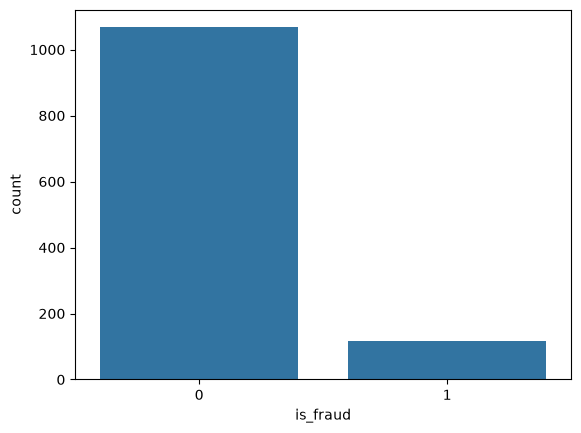

In [66]:
# code here
sns.countplot(df, x = "is_fraud")
plt.show()

**Q2. 카드한드와 월별 평균 지출의 관계를 scatterplot으로 시각화하세요.**

그리고 이 그래프를 통해 알 수 있던 정보를 코드 아래에 적어 봅시다.

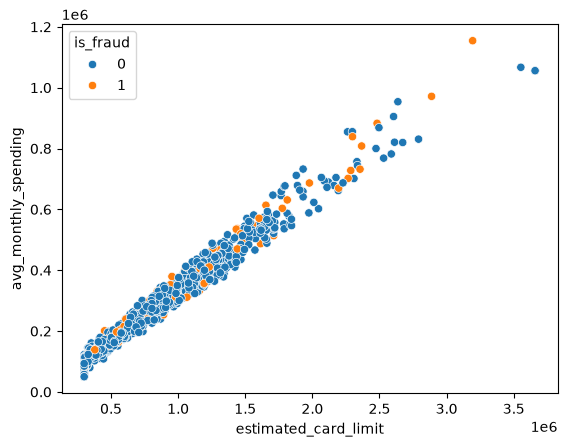

In [68]:
# code here
sns.scatterplot(df, x = "estimated_card_limit", y = "avg_monthly_spending", hue = "is_fraud")
plt.show()

**Q2. 시간별 사기 거래 발생 비율을 라인 그래프로 시각화하세요.**

그리고 이 그래프를 통해 알 수 있던 정보를 코드 아래에 적어 봅시다.

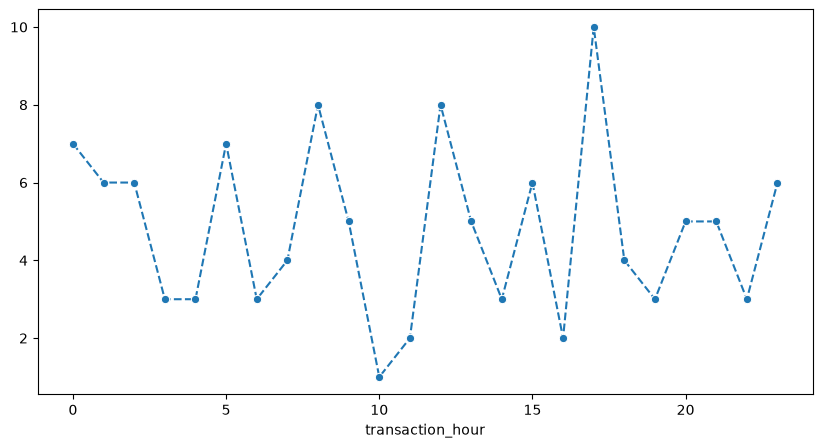

In [94]:
# code here
plt.figure(figsize=(10, 5)) 
df_hour = df.groupby("transaction_hour")["is_fraud"].sum()
sns.lineplot(x = df_hour.index, y = df_hour.values, marker = 'o', linestyle = "--")
plt.show()

## **3. 데이터 전처리하기**

In [123]:
# 전처리 과정 중 데이터가 망가지면 여기서부터 다시!
df = pd.read_csv('https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/credit_card_fraud.csv')
df.head(10)

,transaction_id,transaction_amount,transaction_hour,merchant_category,customer_age,account_tenure_days,avg_monthly_spending,estimated_card_limit,distance_from_home_km,is_foreign_transaction,num_transactions_last_24h,time_since_last_transaction_min,is_fraud
0,100387,15500.0,21,레스토랑,22.0,626,555000.0,1700000.0,30.5,0,2,20.7,0
1,100995,720700.0,6,전자기기,48.0,1459,487200.0,1614000.0,8.0,0,2,139.7,1
2,100152,24800.0,9,주유소,34.0,1614,333100.0,1085000.0,9.2,0,1,23.8,0
3,100652,45200.0,9,주유소,55.0,1881,150000.0,403000.0,1.2,0,1,273.6,0
4,100595,377900.0,1,여행/항공,36.0,853,100400.0,313000.0,55.8,0,6,302.1,1
5,100989,463300.0,8,여행/항공,32.0,2163,1154400.0,3194000.0,3.7,0,3,121.6,1
6,101095,3700.0,18,편의점,37.0,2847,NaN,1108000.0,2.7,0,2,43.0,0
7,101140,129700.0,5,전자기기,49.0,1675,388800.0,1250000.0,1.9,0,1,64.0,0
8,100206,169100.0,17,온라인쇼핑,33.0,1995,130300.0,343000.0,11.8,0,5,35.3,0
9,100082,30500.0,2,주유소,43.0,2939,69100.0,300000.0,9.8,0,3,172.5,0


### **3-1. 중복행 처리하기**

**Q1. 중복된 행이 있는지 확인하고, 만약 존재한다면 제거하세요.**

In [124]:
# code here
df.duplicated().sum()

df = df.drop_duplicates()

**Q2. tranasction_id 컬럼도 삭제해주도록 합시다.**

In [125]:
# code here
df = df.drop("transaction_id", axis = 1)

In [126]:
df

,transaction_amount,transaction_hour,merchant_category,customer_age,account_tenure_days,avg_monthly_spending,estimated_card_limit,distance_from_home_km,is_foreign_transaction,num_transactions_last_24h,time_since_last_transaction_min,is_fraud
0,15500.0,21,레스토랑,22.0,626,555000.0,1700000.0,30.5,0,2,20.7,0
1,720700.0,6,전자기기,48.0,1459,487200.0,1614000.0,8.0,0,2,139.7,1
2,24800.0,9,주유소,34.0,1614,333100.0,1085000.0,9.2,0,1,23.8,0
3,45200.0,9,주유소,55.0,1881,150000.0,403000.0,1.2,0,1,273.6,0
4,377900.0,1,여행/항공,36.0,853,100400.0,313000.0,55.8,0,6,302.1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1180,66000.0,6,레스토랑,63.0,1628,687100.0,2228000.0,11.5,0,5,478.7,0
1181,16700.0,2,편의점,58.0,1474,349800.0,994000.0,50.9,0,1,196.0,0
1182,556500.0,5,전자기기,65.0,2308,NaN,1227000.0,20.5,0,1,441.0,1
1183,76800.0,6,온라인쇼핑,59.0,951,274400.0,805000.0,32.8,0,1,14.2,0


### **3-2. 데이터 분할하기**

**Q1. 학습 데이터와 테스트 데이터를 분리합니다.**
- 학습 데이터와 테스트 데이터를 7:3으로 분할합니다.
- 재현성을 위해 random_state를 101로 설정합니다.
- is_fraud의 비율이 치우쳐져있기에, stratify 옵션을 설정해줍니다.

In [127]:
X = df.drop("is_fraud", axis = 1)
y = df["is_fraud"]

In [128]:
# code here
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101, stratify=y)

### **3-3. 결측치 처리하기**

**Q1. 컬럼별 결측치 개수를 확인하세요.**

In [129]:
# code here
X_train.isnull().sum()

transaction_amount                 29
transaction_hour                    0
merchant_category                   0
customer_age                       20
account_tenure_days                 0
avg_monthly_spending               30
estimated_card_limit                0
distance_from_home_km              36
is_foreign_transaction              0
num_transactions_last_24h           0
time_since_last_transaction_min     0
dtype: int64

**Q2. 모든 결측치를 중앙값으로 대체합니다.**

In [130]:
# code here
numerics_cols = X_train.select_dtypes(include="number")

for c in numerics_cols:
    fill_val = X_train[c].median()
    X_train[c] = X_train[c].fillna(fill_val)
    X_test[c] = X_test[c].fillna(fill_val)

### **3-4. 이상치 처리하기**

**Q1. 각 컬럼의 이상치의 개수를 확인합니다.**

In [131]:
# code here
def find_whisker(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    iqr = Q3 - Q1
    lower = Q1 - (1.5 * iqr)
    upper = Q3 + (1.5 * iqr)
    return (lower, upper)

**Q2. 모든 컬럼들에 대해 clipping을 수행합니다.**

In [133]:
# code here

d = {}
for c in numerics_cols:
    lower, upper = find_whisker(X_train, c)
    d[c] = (lower, upper)
    outliers = ((X_train[c] < lower) | (X_train[c] > upper)).sum()
    print(f"{c} : {outliers}")

transaction_amount : 70
transaction_hour : 0
customer_age : 3
account_tenure_days : 0
avg_monthly_spending : 31
estimated_card_limit : 27
distance_from_home_km : 43
is_foreign_transaction : 70
num_transactions_last_24h : 10
time_since_last_transaction_min : 44


In [134]:
for c in numerics_cols:
    # train, test cliping 하기
    lower, upper = d[c]
    X_train[c] = X_train[c].clip(lower, upper)
    X_test[c] = X_test[c].clip(lower, upper)

In [135]:
for c in numerics_cols:
    lower, upper = find_whisker(X_train, c)
    d[c] = (lower, upper)
    outliers = ((X_train[c] < lower) | (X_train[c] > upper)).sum()


    print(f"{c} : {outliers}")

transaction_amount : 0
transaction_hour : 0
customer_age : 0
account_tenure_days : 0
avg_monthly_spending : 0
estimated_card_limit : 0
distance_from_home_km : 0
is_foreign_transaction : 0
num_transactions_last_24h : 0
time_since_last_transaction_min : 0


### **3-5. Feature Encoding**

**Q1. 업종(merchant_category) 컬럼을 원-핫 인코딩 하세요.**

In [136]:
# code here
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(sparse_output=False, drop="first")

In [137]:
X_train_encoded = ohe.fit_transform(X_train[["merchant_category"]])
X_train_encoded = pd.DataFrame(X_train_encoded, columns = ohe.get_feature_names_out(), index = X_train.index)
X_train_encoded = pd.concat([X_train.drop("merchant_category", axis = 1), X_train_encoded], axis = 1)
X_train_encoded

,transaction_amount,transaction_hour,customer_age,account_tenure_days,avg_monthly_spending,estimated_card_limit,distance_from_home_km,is_foreign_transaction,num_transactions_last_24h,time_since_last_transaction_min,merchant_category_생활용품,merchant_category_여행/항공,merchant_category_온라인쇼핑,merchant_category_전자기기,merchant_category_주유소,merchant_category_편의점
989,114800.0,12,36.0,2584,302000.0,860000.0,36.6,0,1,19.9,0.0,0.0,1.0,0.0,0.0,0.0
5,327300.0,8,32.0,2163,660950.0,2000500.0,3.7,0,3,121.6,0.0,1.0,0.0,0.0,0.0,0.0
122,10200.0,5,25.0,209,523500.0,1591000.0,37.8,0,3,91.9,0.0,0.0,0.0,0.0,0.0,1.0
834,19500.0,16,67.0,3987,229500.0,698000.0,12.7,0,2,65.9,0.0,0.0,0.0,0.0,0.0,1.0
352,142500.0,15,27.0,1379,342800.0,892000.0,5.8,0,3,24.7,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1023,212100.0,7,29.0,977,346600.0,1077000.0,7.0,0,3,5.4,0.0,0.0,0.0,1.0,0.0,0.0
282,59300.0,10,0.0,3790,346700.0,957000.0,34.9,0,4,275.2,0.0,0.0,0.0,0.0,0.0,0.0
500,247700.0,4,64.0,3311,203700.0,700000.0,6.4,0,1,86.3,0.0,0.0,0.0,1.0,0.0,0.0
396,117700.0,16,24.0,3499,74800.0,300000.0,40.6,0,5,149.9,0.0,0.0,1.0,0.0,0.0,0.0


In [138]:
X_test_encoded = ohe.transform(X_test[["merchant_category"]])
X_test_encoded = pd.DataFrame(X_test_encoded, columns = ohe.get_feature_names_out(), index=X_test.index)
X_test_encoded = pd.concat([X_test.drop("merchant_category", axis = 1), X_test_encoded], axis = 1)

X_test_encoded

,transaction_amount,transaction_hour,customer_age,account_tenure_days,avg_monthly_spending,estimated_card_limit,distance_from_home_km,is_foreign_transaction,num_transactions_last_24h,time_since_last_transaction_min,merchant_category_생활용품,merchant_category_여행/항공,merchant_category_온라인쇼핑,merchant_category_전자기기,merchant_category_주유소,merchant_category_편의점
873,60900.0,15,43.0,3588,259700.0,934000.0,15.3,0,2,99.2,1.0,0.0,0.0,0.0,0.0,0.0
1124,94700.0,14,42.0,1045,199000.0,675000.0,25.6,0,3,375.6,0.0,0.0,0.0,1.0,0.0,0.0
829,218100.0,8,37.0,1804,304400.0,833000.0,1.0,0,3,60.5,0.0,1.0,0.0,0.0,0.0,0.0
786,151200.0,9,58.0,3904,200100.0,552000.0,5.8,0,5,85.9,0.0,1.0,0.0,0.0,0.0,0.0
1101,66550.0,14,34.0,1806,163100.0,503000.0,49.7,0,1,288.8,0.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
662,56400.0,12,64.0,310,191400.0,586000.0,19.3,0,1,63.6,0.0,0.0,1.0,0.0,0.0,0.0
582,255000.0,8,71.0,51,379500.0,954000.0,17.6,0,0,37.7,0.0,0.0,1.0,0.0,0.0,0.0
181,147100.0,18,25.0,1383,111400.0,309000.0,9.8,0,2,98.7,0.0,0.0,0.0,1.0,0.0,0.0
831,127600.0,23,72.0,3739,430300.0,1427000.0,5.6,0,1,232.4,0.0,0.0,1.0,0.0,0.0,0.0


## **4. 모델링**

**Q1. DecisionTreeClassifier를 import 해둡시다.**
- 모든 Boosting 모델은 결국 트리를 활용합니다.

In [139]:
# code here
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier()

tree_model.fit(X_train_encoded, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

**Q2. evaluate_model 함수를 작성합니다.**
- y_test, y_pred를 넣으면 정확도와 분류 리포트, 그리고 혼동 행렬을 그려주는 함수입니다.

In [140]:
# code here
y_pred = tree_model.predict(X_test_encoded)

In [142]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

def evaluate_model(y_test, y_pred):
    print(f"accuracy : {accuracy_score(y_test, y_pred)}")
    print(classification_report(y_test, y_pred))

    plt.figure(figsize=(5,3))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap="Blues")
    plt.show()

accuracy : 0.8840579710144928
              precision    recall  f1-score   support

           0       0.93      0.94      0.94       310
           1       0.42      0.37      0.39        35

    accuracy                           0.88       345
   macro avg       0.67      0.66      0.66       345
weighted avg       0.88      0.88      0.88       345



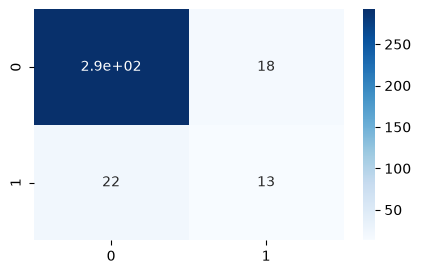

In [143]:
evaluate_model(y_test, y_pred)

### **4-1. AdaBoost**

**Q1. AdaBoost모델을 생성하고, 학습시켜 봅시다.**
- DecisionTreeClassifier의 max_depth=3의 스텀프를 활용합니다.
- n_estimators = 100
- learning_rate = 0.05
- random_state=101

In [145]:
# code here

from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(
    n_estimators = 100,
    learning_rate = 0.05,
    random_state = 101
)

In [146]:
adaboost.fit(X_train_encoded, y_train)

,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.05
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",101
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.07,0.08,0.11,...,0.44,0.44,0.45]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[0.13,0.12,0.11,...,0.01,0.01,0.01]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...tate=70431583), DecisionTreeC...ate=225658379), DecisionTreeC...ate=303514961), DecisionTreeC...te=1944264518), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](16,)","[0.96,0. ,0. ,...,0. ,0. ,0.01]"


In [147]:
y_pred = adaboost.predict(X_test_encoded)

accuracy : 0.9246376811594202
              precision    recall  f1-score   support

           0       0.94      0.98      0.96       310
           1       0.71      0.43      0.54        35

    accuracy                           0.92       345
   macro avg       0.83      0.70      0.75       345
weighted avg       0.92      0.92      0.92       345



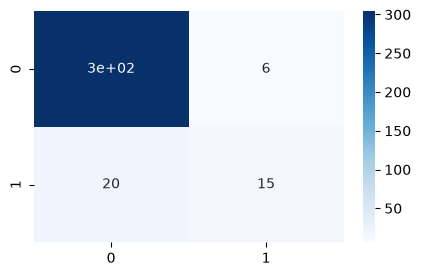

In [148]:
evaluate_model(y_test, y_pred)

### **4-2. GBM**

**Q1. GradientBoosting모델을 생성하고, 학습시켜 봅시다.**

- max_depth=3
- n_estimators = 100
- learning_rate = 0.05
- subsample=0.8
- random_state=101

In [151]:
# code here
from sklearn.ensemble import GradientBoostingClassifier

gbm = GradientBoostingClassifier(
    max_depth = 3,
    n_estimators= 100,
    learning_rate=0.05,
    subsample=0.8,
    random_state = 101
)

In [152]:
gbm.fit(X_train_encoded, y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.05
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",101
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (

accuracy : 0.9391304347826087
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       310
           1       0.77      0.57      0.66        35

    accuracy                           0.94       345
   macro avg       0.86      0.78      0.81       345
weighted avg       0.93      0.94      0.94       345



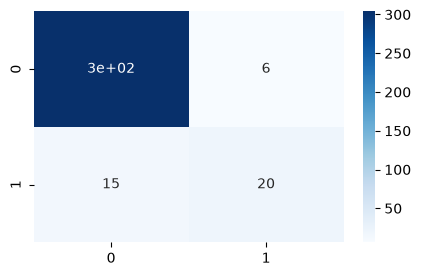

In [154]:
y_pred = gbm.predict(X_test_encoded)
evaluate_model(y_test, y_pred)

### **4-3. XGBoost**

** XGBoost 모델은 로컬에서 활용할때 설치가 필요합니다.**
```
!pip install xgboost
```

**Q1. XGBoost모델을 생성하고, 학습시켜 봅시다.**

- max_depth=3
- n_estimators = 100
- learning_rate = 0.05
- subsample=0.8
- random_state=101

In [162]:
# code here
import xgboost as xgb

xgb_model = xgb.XGBClassifier(
    max_depth = 3,
    n_estimators = 100,
    learning_rate = 0.05,
    subsample = 0.8,
    random_state = 101,
    device = "cuda"
)

In [163]:
xgb_model.fit(X_train_encoded, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


accuracy : 0.9391304347826087
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       310
           1       0.75      0.60      0.67        35

    accuracy                           0.94       345
   macro avg       0.85      0.79      0.82       345
weighted avg       0.93      0.94      0.94       345



c:\Users\user\AppData\Local\Programs\Python\Python315\Lib\site-packages\xgboost\core.py:569: UserWarning: [15:45:00] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


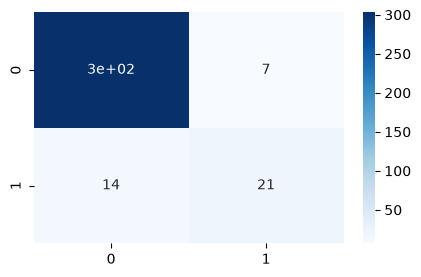

In [164]:
y_pred = xgb_model.predict(X_test_encoded)
evaluate_model(y_test, y_pred)

### **4-4. LigtGBM**

**Q1. GradientBoosting모델을 생성하고, 학습시켜 봅시다.**
- max_depth=3
- n_estimators = 100
- learning_rate = 0.05
- subsample=0.8
- random_state=101

In [ ]:
# code here
import lightgbm as lgbm

lgbm_model = lgbm.LGBMClassifier(
    max_depth = 3,
    n_estimators = 100,
    learning_rate = 0.05,
    subsample=0.8,
    random_state = 101,
    num_leaves= 5   # 2 * max_depth 보다 작거나 같게 하는것을 권장
)


In [174]:
lgbm_model.fit(X_train_encoded, y_train)

[LightGBM] [Info] Number of positive: 80, number of negative: 725
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000109 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1626
[LightGBM] [Info] Number of data points in the train set: 805, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.099379 -> initscore=-2.204145
[LightGBM] [Info] Start training from score -2.204145


,num_leaves,5
,max_depth,3
,learning_rate,0.05
,subsample,0.8
,random_state,101
,boosting_type,'gbdt'
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


accuracy : 0.9304347826086956
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       310
           1       0.72      0.51      0.60        35

    accuracy                           0.93       345
   macro avg       0.83      0.75      0.78       345
weighted avg       0.92      0.93      0.93       345



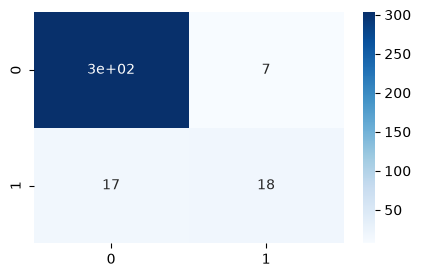

In [175]:
y_pred = lgbm_model.predict(X_test_encoded)
evaluate_model(y_test, y_pred)

### **4-5. Hyperparameter Tuning**

**Q1. 원하는 모델을 하나 선정하여 하이퍼파라미터 튜닝을 해봅니다.**

- 여기서부터는 정답이 없습니다.
- 여러 parameter tuning을 통해 최대한 좋은 결과를 제출해볼 수 있도록 해 주세요.
- GridSearch로 많은 파라미터를 확인하는 것은 정말 오랜 시간이 걸릴 수 있습니다.(2~5시간)
- 만약 필요하다면, 데이터 전처리를 더 해보는 방향으로 진행해보세요.

In [197]:
# code here
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    "n_estimators": [300, 500],
    "learning_rate": [0.01, 0.05],
    "max_depth": [5, 7],             
    "min_child_weight": [1, 3],
    "gamma": [0.1, 0.5],             
    "subsample": [0.8],              
    "colsample_bytree": [0.8],
    # --- 새로 추가된 고급 파라미터 ---
    "scale_pos_weight": [10, 50],    # 불균형 데이터 핵심 (사기 데이터에 가중치 부여)
    "reg_alpha": [0.01, 0.1, 1],     # L1 규제: 영향력이 적은 변수(피처)를 무시하여 노이즈 제거
    "reg_lambda": [1, 5, 10]         # L2 규제: 특정 가중치가 너무 커지는 것을 막아 일반화 성능 향상
}

In [198]:
grid_search = GridSearchCV(
    xgb.XGBClassifier(random_state=101, tree_method='hist'),
    param_grid=param_grid,
    cv=3,            # 탐색할 조합이 많아졌으므로 CV를 3으로 줄여 연산 시간 단축
    scoring="f1",    # 중요: 정확도(accuracy) 대신 F1 스코어를 기준으로 가장 좋은 모델 탐색
    verbose=2,
    n_jobs=-1
)

In [199]:
grid_search.fit(X_train_encoded, y_train)

Fitting 3 folds for each of 576 candidates, totalling 1728 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'colsample_bytree': [0.8], 'gamma': [0.1, 0.5], 'learning_rate': [0.01, 0.05], 'max_depth': [5, 7], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selecti

In [200]:
model = grid_search.best_estimator_

In [201]:
y_pred = model.predict(X_test_encoded)

accuracy : 0.927536231884058
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       310
           1       0.68      0.54      0.60        35

    accuracy                           0.93       345
   macro avg       0.81      0.76      0.78       345
weighted avg       0.92      0.93      0.92       345



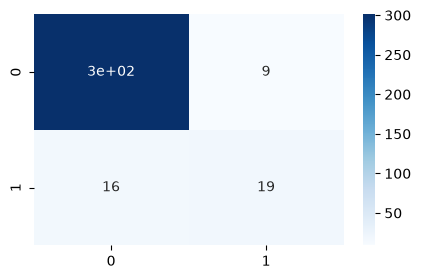

In [181]:
evaluate_model(y_test, y_pred)

## **5. 채점하기**

데이터 전처리 방법과 학습된 모델을 활용하여 미공개 데이터에 대해 transaction_id에 일치하는 예측 결과를 DataFrame의 "is_fraud" 컬럼에 기입하고 .csv파일로 저장하여 제출합니다.

**미공개 데이터 URL:**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/credit_card_fraud_submission.csv

In [192]:
import pandas as pd
sub = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/credit_card_fraud_submission.csv")
sub.head()

,transaction_id,transaction_amount,transaction_hour,merchant_category,customer_age,account_tenure_days,avg_monthly_spending,estimated_card_limit,distance_from_home_km,is_foreign_transaction,num_transactions_last_24h,time_since_last_transaction_min
0,900001,148100.0,6,생활용품,56,954,70700.0,300000.0,7.7,1,0,397.3
1,900002,49400.0,18,온라인쇼핑,25,1634,186600.0,549000.0,4.2,0,1,91.0
2,900003,5200.0,1,편의점,47,232,113600.0,349000.0,12.7,0,1,32.6
3,900004,218000.0,12,전자기기,64,720,157300.0,395000.0,22.9,0,1,132.2
4,900005,153600.0,19,레스토랑,21,3215,103000.0,300000.0,13.9,0,2,134.1


In [193]:
# code here

sub_encoded = ohe.transform(sub[["merchant_category"]])
sub_encoded = pd.DataFrame(sub_encoded, columns = ohe.get_feature_names_out(), index = sub.index)
sub_encoded = pd.concat([sub.drop("merchant_category", axis = 1), sub_encoded], axis = 1)

In [195]:
ids = sub_encoded["transaction_id"]

In [196]:
sub_encoded = sub_encoded.drop("transaction_id",axis = 1)

In [203]:
y_pred_sub = model.predict(sub_encoded)

In [205]:
y_pred_sub = pd.DataFrame(y_pred_sub, columns = ["is_fraud"])

In [208]:
pd.concat([ids, y_pred_sub], axis = 1).to_csv("anomal05.csv", index = False)